In [5]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Recreate the exact chronological split
train = bike_series.loc[:'2018-08-13 11:00:00']

validation = bike_series.loc[
    '2018-08-13 12:00:00':'2018-10-07 05:00:00'
]

test = bike_series.loc['2018-10-07 06:00:00':]

# Verify the split
print("Training:", len(train))
print("Validation:", len(validation))
print("Test:", len(test))

print("\nMissing values:")
print("Training:", train.isna().sum())
print("Validation:", validation.isna().sum())
print("Test:", test.isna().sum())

Training: 6132
Validation: 1314
Test: 1314

Missing values:
Training: 0
Validation: 0
Test: 0


In [8]:
adf_train = adfuller(train)

print("ADF Statistic:", adf_train[0])
print("p-value:", adf_train[1])

print("\nCritical Values:")
for key, value in adf_train[4].items():
    print(f"{key}: {value}")

ADF Statistic: -6.003674978390878
p-value: 1.634628751526936e-07

Critical Values:
1%: -3.4314229957838465
5%: -2.8620141668881423
10%: -2.5670223963782823


C:\Users\User\AppData\Local\Temp\ipykernel_20288\1228095701.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_train = adfuller(train)


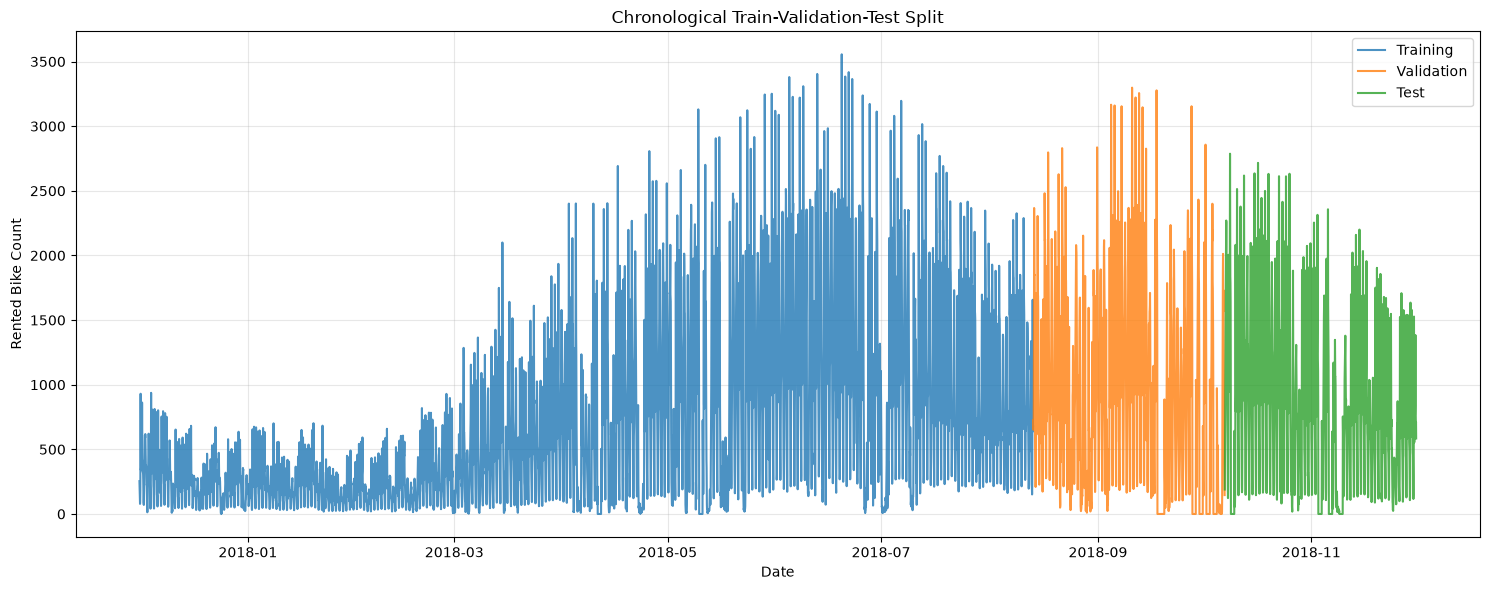

In [9]:
plt.figure(figsize=(15, 6))

plt.plot(train.index, train, label="Training", alpha=0.8)
plt.plot(validation.index, validation, label="Validation", alpha=0.8)
plt.plot(test.index, test, label="Test", alpha=0.8)

plt.title("Chronological Train-Validation-Test Split")
plt.xlabel("Date")
plt.ylabel("Rented Bike Count")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "../results/figures/data_split.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

ACF PACF 

<Figure size 1400x500 with 0 Axes>

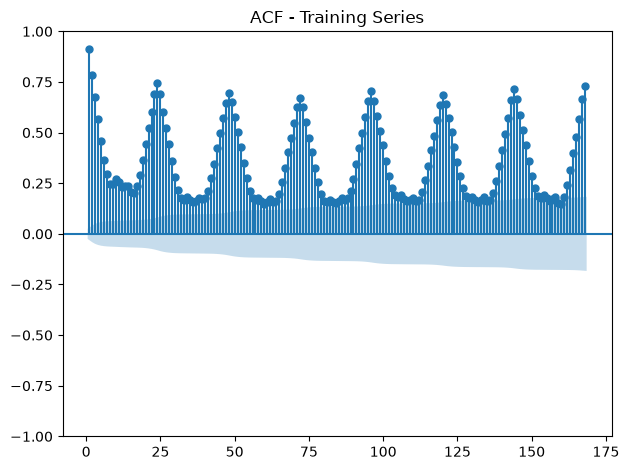

<Figure size 1400x500 with 0 Axes>

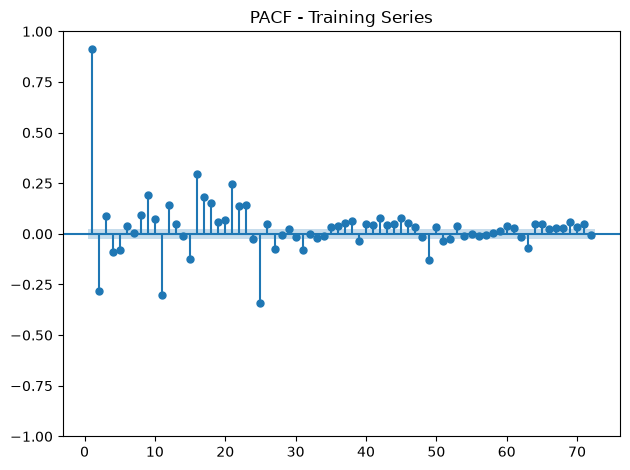

In [10]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

# ACF: examine autocorrelation up to one week
plt.figure(figsize=(14, 5))
plot_acf(train, lags=168, zero=False)
plt.title("ACF - Training Series")
plt.tight_layout()
plt.savefig("../results/figures/acf_training.png", dpi=300)
plt.show()

# PACF: examine direct autocorrelation up to three days
plt.figure(figsize=(14, 5))
plot_pacf(train, lags=72, method="ywm", zero=False)
plt.title("PACF - Training Series")
plt.tight_layout()
plt.savefig("../results/figures/pacf_training.png", dpi=300)
plt.show()

In [11]:
from statsmodels.tsa.stattools import acf, pacf

acf_values = acf(train, nlags=168)
pacf_values = pacf(train, nlags=72, method="ywm")

selected_lags = [1, 2, 3, 6, 12, 24, 25, 48, 72, 168]

print("ACF VALUES")
for lag in selected_lags:
    if lag < len(acf_values):
        print(f"Lag {lag}: {acf_values[lag]:.4f}")

print("\nPACF VALUES")
for lag in [1, 2, 3, 6, 12, 24, 25, 48, 72]:
    print(f"Lag {lag}: {pacf_values[lag]:.4f}")

ACF VALUES
Lag 1: 0.9122
Lag 2: 0.7844
Lag 3: 0.6733
Lag 6: 0.3670
Lag 12: 0.2328
Lag 24: 0.7425
Lag 25: 0.6890
Lag 48: 0.6945
Lag 72: 0.6725
Lag 168: 0.7289

PACF VALUES
Lag 1: 0.9122
Lag 2: -0.2843
Lag 3: 0.0890
Lag 6: 0.0369
Lag 12: 0.1412
Lag 24: -0.0264
Lag 25: -0.3423
Lag 48: -0.0141
Lag 72: -0.0045


In [12]:
# Calculate ACF and its confidence intervals
acf_values, acf_conf = acf(
    train,
    nlags=168,
    alpha=0.05
)

# Calculate PACF and its confidence intervals
pacf_values, pacf_conf = pacf(
    train,
    nlags=72,
    alpha=0.05,
    method="ywm"
)

print("ACF significant lags:")
for lag in range(1, len(acf_values)):
    lower, upper = acf_conf[lag]
    if lower > 0 or upper < 0:
        if lag <= 30 or lag in [48, 72, 96, 120, 144, 168]:
            print(f"Lag {lag}: {acf_values[lag]:.4f}")

print("\nPACF significant lags:")
for lag in range(1, len(pacf_values)):
    lower, upper = pacf_conf[lag]
    if lower > 0 or upper < 0:
        print(f"Lag {lag}: {pacf_values[lag]:.4f}")

ACF significant lags:
Lag 1: 0.9122
Lag 2: 0.7844
Lag 3: 0.6733
Lag 4: 0.5687
Lag 5: 0.4604
Lag 6: 0.3670
Lag 7: 0.2935
Lag 8: 0.2476
Lag 9: 0.2458
Lag 10: 0.2719
Lag 11: 0.2544
Lag 12: 0.2328
Lag 13: 0.2339
Lag 14: 0.2378
Lag 15: 0.2086
Lag 16: 0.2017
Lag 17: 0.2343
Lag 18: 0.2923
Lag 19: 0.3637
Lag 20: 0.4438
Lag 21: 0.5218
Lag 22: 0.6021
Lag 23: 0.6882
Lag 24: 0.7425
Lag 25: 0.6890
Lag 26: 0.6019
Lag 27: 0.5206
Lag 28: 0.4422
Lag 29: 0.3580
Lag 30: 0.2805
Lag 48: 0.6945
Lag 72: 0.6725
Lag 96: 0.7030
Lag 120: 0.6849
Lag 144: 0.7158
Lag 168: 0.7289

PACF significant lags:
Lag 1: 0.9122
Lag 2: -0.2843
Lag 3: 0.0890
Lag 4: -0.0884
Lag 5: -0.0799
Lag 6: 0.0369
Lag 8: 0.0944
Lag 9: 0.1922
Lag 10: 0.0751
Lag 11: -0.3021
Lag 12: 0.1412
Lag 13: 0.0467
Lag 15: -0.1259
Lag 16: 0.2943
Lag 17: 0.1823
Lag 18: 0.1533
Lag 19: 0.0596
Lag 20: 0.0708
Lag 21: 0.2444
Lag 22: 0.1399
Lag 23: 0.1405
Lag 24: -0.0264
Lag 25: -0.3423
Lag 26: 0.0475
Lag 27: -0.0731
Lag 31: -0.0774
Lag 35: 0.0342
Lag 36: 0.0396

C:\Users\User\AppData\Local\Temp\ipykernel_20288\1627181846.py:2: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  acf_values, acf_conf = acf(


In [13]:
important_lags = [1, 2, 3, 6, 12, 18, 23, 24, 25,
                  47, 48, 49, 71, 72, 73,
                  167, 168]

print("ACF AND PACF CONFIDENCE CHECK")

for lag in important_lags:
    if lag < len(acf_values):
        a_lower, a_upper = acf_conf[lag]
        print(
            f"Lag {lag:3d} | "
            f"ACF: {acf_values[lag]:.4f} "
            f"({'Significant' if a_lower > 0 or a_upper < 0 else 'Not significant'})"
        )

print("\nPACF RESULTS")

for lag in range(1, len(pacf_values)):
    p_lower, p_upper = pacf_conf[lag]

    if p_lower > 0 or p_upper < 0:
        if lag <= 30 or lag in [48, 72]:
            print(
                f"Lag {lag:3d} | "
                f"PACF: {pacf_values[lag]:.4f} "
                f"(Significant)"
            )

ACF AND PACF CONFIDENCE CHECK
Lag   1 | ACF: 0.9122 (Significant)
Lag   2 | ACF: 0.7844 (Significant)
Lag   3 | ACF: 0.6733 (Significant)
Lag   6 | ACF: 0.3670 (Significant)
Lag  12 | ACF: 0.2328 (Significant)
Lag  18 | ACF: 0.2923 (Significant)
Lag  23 | ACF: 0.6882 (Significant)
Lag  24 | ACF: 0.7425 (Significant)
Lag  25 | ACF: 0.6890 (Significant)
Lag  47 | ACF: 0.6478 (Significant)
Lag  48 | ACF: 0.6945 (Significant)
Lag  49 | ACF: 0.6511 (Significant)
Lag  71 | ACF: 0.6250 (Significant)
Lag  72 | ACF: 0.6725 (Significant)
Lag  73 | ACF: 0.6274 (Significant)
Lag 167 | ACF: 0.6636 (Significant)
Lag 168 | ACF: 0.7289 (Significant)

PACF RESULTS
Lag   1 | PACF: 0.9122 (Significant)
Lag   2 | PACF: -0.2843 (Significant)
Lag   3 | PACF: 0.0890 (Significant)
Lag   4 | PACF: -0.0884 (Significant)
Lag   5 | PACF: -0.0799 (Significant)
Lag   6 | PACF: 0.0369 (Significant)
Lag   8 | PACF: 0.0944 (Significant)
Lag   9 | PACF: 0.1922 (Significant)
Lag  10 | PACF: 0.0751 (Significant)
Lag  11 

In [14]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Candidate 1: ARIMA(1,0,1)
model_101 = ARIMA(
    train,
    order=(1, 0, 1)
)

results_101 = model_101.fit()

# Forecast the validation period
forecast_101 = results_101.forecast(
    steps=len(validation)
)

# Candidate 2: ARIMA(2,0,0)
model_200 = ARIMA(
    train,
    order=(2, 0, 0)
)

results_200 = model_200.fit()

# Forecast the validation period
forecast_200 = results_200.forecast(
    steps=len(validation)
)

# Evaluate both models
comparison = pd.DataFrame({
    "Model": ["ARIMA(1,0,1)", "ARIMA(2,0,0)"],
    "MAE": [
        mean_absolute_error(validation, forecast_101),
        mean_absolute_error(validation, forecast_200)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(validation, forecast_101)),
        np.sqrt(mean_squared_error(validation, forecast_200))
    ]
})

print(comparison.to_string(index=False))

       Model        MAE       RMSE
ARIMA(1,0,1) 596.654003 750.157554
ARIMA(2,0,0) 596.641665 750.152466


In [15]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Daily seasonal SARIMA model
sarima_model = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 24),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_results = sarima_model.fit(disp=False)

print(sarima_results.summary())

                                     SARIMAX Results                                      
Dep. Variable:                  Rented Bike Count   No. Observations:                 6132
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 24)   Log Likelihood              -40003.143
Date:                            Tue, 17 Nov 2026   AIC                          80016.286
Time:                                    17:51:43   BIC                          80049.872
Sample:                                12-01-2017   HQIC                         80027.939
                                     - 08-13-2018                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8253      0.005    151.298      0.000       0.815       0.836
ma.L1          0.2701      0.009   

In [16]:
# Forecast the complete validation period
sarima_forecast = sarima_results.forecast(
    steps=len(validation)
)

# Calculate validation errors
sarima_mae = mean_absolute_error(
    validation, sarima_forecast
)

sarima_rmse = np.sqrt(
    mean_squared_error(validation, sarima_forecast)
)

print("SARIMA(1,0,1)(1,0,1,24)")
print("MAE:", sarima_mae)
print("RMSE:", sarima_rmse)

SARIMA(1,0,1)(1,0,1,24)
MAE: 424.82928761052426
RMSE: 609.3799122480455


In [17]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Extract model residuals
sarima_residuals = sarima_results.resid.dropna()

# Ljung-Box test at daily and weekly lags
ljung_results = acorr_ljungbox(
    sarima_residuals,
    lags=[24, 48, 168],
    return_df=True
)

print("LJUNG-BOX TEST")
print(ljung_results)

# Check AR roots
print("\nAR ROOTS")
print(np.abs(sarima_results.arroots))

# Check MA roots
print("\nMA ROOTS")
print(np.abs(sarima_results.maroots))

LJUNG-BOX TEST
         lb_stat      lb_pvalue
24    649.254412  1.135526e-121
48    882.034091  7.978373e-154
168  2618.220595   0.000000e+00

AR ROOTS
[0.99991624 0.99991624 0.99991624 0.99991624 0.99991624 0.99991624
 0.99991624 0.99991624 0.99991624 0.99991624 0.99991624 0.99991624
 0.99991624 0.99991624 0.99991624 0.99991624 0.99991624 0.99991624
 0.99991624 0.99991624 0.99991624 0.99991624 0.99991624 0.99991624
 1.21172115]

MA ROOTS
[1.00253677 1.00253677 1.00253677 1.00253677 1.00253677 1.00253677
 1.00253677 1.00253677 1.00253677 1.00253677 1.00253677 1.00253677
 1.00253677 1.00253677 1.00253677 1.00253677 1.00253677 1.00253677
 1.00253677 1.00253677 1.00253677 1.00253677 1.00253677 1.00253677
 3.70208973]


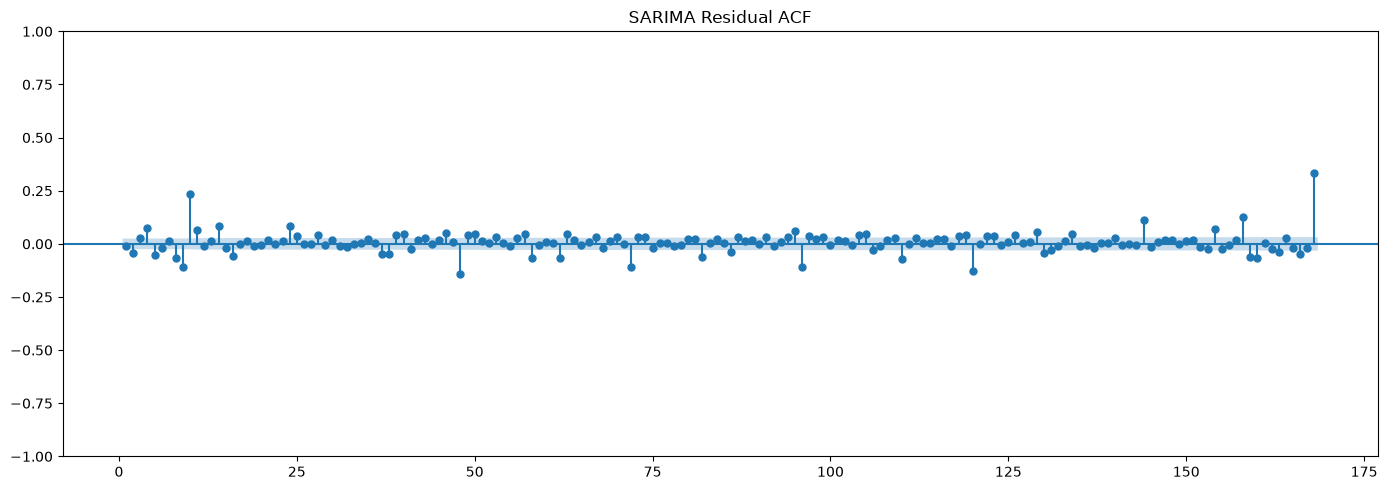

In [18]:
fig, ax = plt.subplots(figsize=(14, 5))

plot_acf(
    sarima_residuals,
    lags=168,
    zero=False,
    ax=ax
)

ax.set_title("SARIMA Residual ACF")
plt.tight_layout()

plt.savefig(
    "../results/figures/sarima_residual_acf.png",
    dpi=300
)

plt.show()

In [19]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Candidate 1: Seasonal MA only
model_sma = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(0, 0, 1, 24)
)

results_sma = model_sma.fit(disp=False)

# Candidate 2: Seasonal AR only
model_sar = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(1, 0, 0, 24)
)

results_sar = model_sar.fit(disp=False)

# Generate validation forecasts
forecast_sma = results_sma.forecast(steps=len(validation))
forecast_sar = results_sar.forecast(steps=len(validation))

# Compare validation accuracy
models_comparison = pd.DataFrame({
    "Model": [
        "SARIMA(1,0,1)(0,0,1,24)",
        "SARIMA(1,0,1)(1,0,0,24)"
    ],
    "MAE": [
        mean_absolute_error(validation, forecast_sma),
        mean_absolute_error(validation, forecast_sar)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(validation, forecast_sma)),
        np.sqrt(mean_squared_error(validation, forecast_sar))
    ]
})

print(models_comparison.to_string(index=False))

                  Model        MAE        RMSE
SARIMA(1,0,1)(0,0,1,24) 865.673124 1122.447313
SARIMA(1,0,1)(1,0,0,24) 848.303757 1106.713599


In [20]:
model_sarima_diff = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(1, 1, 1, 24)
)

results_sarima_diff = model_sarima_diff.fit(disp=False)

forecast_sarima_diff = results_sarima_diff.forecast(
    steps=len(validation)
)

mae_diff = mean_absolute_error(
    validation,
    forecast_sarima_diff
)

rmse_diff = np.sqrt(
    mean_squared_error(
        validation,
        forecast_sarima_diff
    )
)

print("SARIMA(1,0,1)(1,1,1,24)")
print("MAE:", mae_diff)
print("RMSE:", rmse_diff)

SARIMA(1,0,1)(1,1,1,24)
MAE: 418.1487568427194
RMSE: 580.6476529237615


In [21]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Extract residuals
residuals_diff = results_sarima_diff.resid.dropna()

# Ljung-Box test
ljung_diff = acorr_ljungbox(
    residuals_diff,
    lags=[24, 48, 168],
    return_df=True
)

print("LJUNG-BOX TEST")
print(ljung_diff)

# Check AR roots
print("\nAR ROOTS")
print(np.abs(results_sarima_diff.arroots))

# Check MA roots
print("\nMA ROOTS")
print(np.abs(results_sarima_diff.maroots))

LJUNG-BOX TEST
         lb_stat      lb_pvalue
24    566.976827  1.889742e-104
48    781.999116  2.659897e-133
168  2237.030017   0.000000e+00

AR ROOTS
[1.10373212 1.10373212 1.10373212 1.10373212 1.10373212 1.10373212
 1.10373212 1.10373212 1.10373212 1.10373212 1.10373212 1.10373212
 1.10373212 1.10373212 1.10373212 1.10373212 1.10373212 1.10373212
 1.10373212 1.10373212 1.10373212 1.10373212 1.10373212 1.10373212
 1.21311981]

MA ROOTS
[1.00246908 1.00246908 1.00246908 1.00246908 1.00246908 1.00246908
 1.00246908 1.00246908 1.00246908 1.00246908 1.00246908 1.00246908
 1.00246908 1.00246908 1.00246908 1.00246908 1.00246908 1.00246908
 1.00246908 1.00246908 1.00246908 1.00246908 1.00246908 1.00246908
 3.74598208]


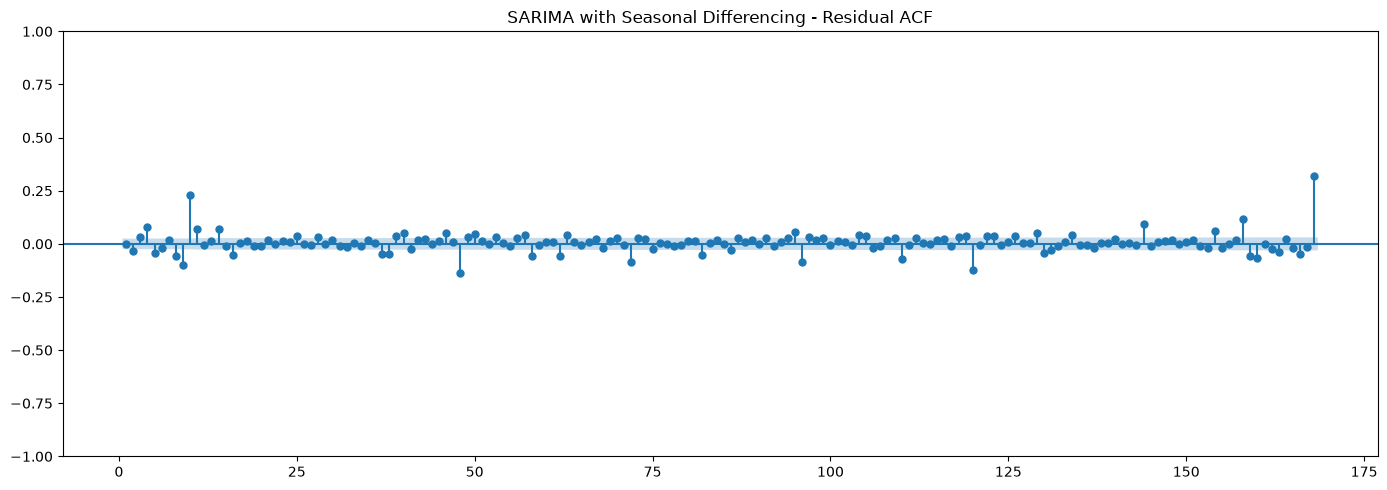

In [22]:
fig, ax = plt.subplots(figsize=(14, 5))

plot_acf(
    residuals_diff,
    lags=168,
    zero=False,
    ax=ax
)

ax.set_title("SARIMA with Seasonal Differencing - Residual ACF")
plt.tight_layout()

plt.savefig(
    "../results/figures/sarima_differenced_residual_acf.png",
    dpi=300
)

plt.show()